[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erolrecep/datascience_from_yesterday_to_tomorrow/blob/main/hands-on/01_f1_data_generation_and_visualization.ipynb)

# Lab 1: F1 Telemetry Generation & Exploratory Data Analysis
### Hands-On Laboratory — Session 1

Welcome to the hands-on laboratory! Today we explore a core pillar of modern data science: **synthetic data generation**, **telemetry analysis**, and **exploratory data visualization**.

#### Why Synthetic Telemetry?
In domains ranging from aerospace and autonomous vehicles to high-performance motorsport (Formula 1), collecting edge-case real-world data can be dangerous, proprietary, or cost-prohibitive. As data scientists, we frequently build **probabilistic physics-informed simulation models** to synthesize realistic telemetry inside our local development environments.

#### Objectives of this Notebook:
1. Formulate a deterministic, physics-informed data generator for an entire Formula 1 race (53 Laps at the Autodromo Nazionale Monza).
2. Generate consistent telemetry across 20 drivers and 10 teams (`seed=42`) so that all downstream analytics remain reproducible.
3. Save the clean telemetry dataset to `f1_monza_race_data.csv`.
4. Perform exploratory data analysis with production-grade visualizations (Pace progression, Tyre degradation curves, Speed trap correlation, and Leaderboard bump charts).


In [1]:
# --- Environment & Google Colab Bootstrap ---
import os
import sys
import urllib.request

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Detected Google Colab environment. Verifying dependencies...")
    !pip install -q pandas numpy matplotlib scikit-learn

CSV_FILE = "f1_monza_race_data.csv"
if not os.path.exists(CSV_FILE) and "01_f1_data_generation_and_visualization.ipynb" != "01_f1_data_generation_and_visualization.ipynb":
    print(f"'{CSV_FILE}' not found locally. Fetching directly from GitHub repository...")
    url = f"https://raw.githubusercontent.com/erolrecep/datascience_from_yesterday_to_tomorrow/main/hands-on/{CSV_FILE}"
    try:
        urllib.request.urlretrieve(url, CSV_FILE)
        print("Dataset successfully downloaded from repository.")
    except Exception as e:
        print(f"Direct download failed ({e}). Generating dataset from simulation engine...")
        from f1_simulation import generate_f1_race_telemetry
        df_gen = generate_f1_race_telemetry(seed=42)
        df_gen.to_csv(CSV_FILE, index=False)
        print("Generated dataset from simulation engine.")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set aesthetic visual defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully.")


Environment initialized successfully.


## Part 1: Physics-Informed Data Generation

A Formula 1 car's lap time at Monza is determined by several core physical variables:
1. **Base Circuit Pace ($T_{	ext{base}}$)**: Monza baseline lap time is approximately $84.0$ seconds.
2. **Car Aerodynamics & Engine Power ($\Delta_{	ext{car}}$)**: High-downforce and low-drag efficiency (e.g., Red Bull, McLaren, Ferrari).
3. **Driver Skill Factor ($\Delta_{	ext{driver}}$)**: Cornering precision, throttle modulation, and tyre preservation.
4. **Fuel Burn ($\Delta_{	ext{fuel}}$)**: Cars start with $100\text{ kg}$ of fuel. Fuel burns at $\approx 1.8\text{ kg/lap}$. In F1, $10\text{ kg}$ costs $\approx 0.33\text{s}$. As fuel burns off, the car gets progressively lighter and faster!
5. **Tyre Degradation ($\Delta_{	ext{tyre}}$)**: Progressive grip loss following a power-law wear curve:
   $$\Delta_{	ext{tyre}} = (\text{tyre\_age})^{1.15} \times \text{deg\_rate}$$
6. **Pit Stop Delta ($\Delta_{	ext{pit}}$)**: Traversing the pit lane at $80\text{ km/h}$ plus stationary tyre change costs $\approx 22.5\text{s}$.
7. **Stochastic Micro-Variations ($\epsilon$)**: DRS battles, traffic, minor lockups drawn from $\mathcal{N}(0, 0.12)$.

Let's define the 20-driver grid with authentic team colors, performance indices, and planned pit strategies:


In [2]:
# Driver grid configuration
DRIVERS_GRID = [
    {"driver": "VER", "name": "Max Verstappen", "team": "Red Bull Racing", "car_base": 9.6, "dry_skill": 9.8, "wet_skill": 9.9, "color": "#1E41B0", "pit_laps": [24]},
    {"driver": "NOR", "name": "Lando Norris", "team": "McLaren", "car_base": 9.5, "dry_skill": 9.6, "wet_skill": 9.5, "color": "#FF8000", "pit_laps": [22]},
    {"driver": "LEC", "name": "Charles Leclerc", "team": "Ferrari", "car_base": 9.3, "dry_skill": 9.7, "wet_skill": 9.4, "color": "#E80020", "pit_laps": [20]},
    {"driver": "HAM", "name": "Lewis Hamilton", "team": "Mercedes", "car_base": 9.1, "dry_skill": 9.6, "wet_skill": 9.95, "color": "#27F4D2", "pit_laps": [26]},
    {"driver": "PIA", "name": "Oscar Piastri", "team": "McLaren", "car_base": 9.5, "dry_skill": 9.4, "wet_skill": 9.3, "color": "#E56B00", "pit_laps": [23]},
    {"driver": "SAI", "name": "Carlos Sainz", "team": "Ferrari", "car_base": 9.3, "dry_skill": 9.4, "wet_skill": 9.3, "color": "#CC0000", "pit_laps": [21]},
    {"driver": "RUS", "name": "George Russell", "team": "Mercedes", "car_base": 9.1, "dry_skill": 9.4, "wet_skill": 9.4, "color": "#00A19B", "pit_laps": [25]},
    {"driver": "PER", "name": "Sergio Perez", "team": "Red Bull Racing", "car_base": 9.6, "dry_skill": 8.9, "wet_skill": 8.8, "color": "#001A72", "pit_laps": [27]},
    {"driver": "ALO", "name": "Fernando Alonso", "team": "Aston Martin", "car_base": 8.7, "dry_skill": 9.5, "wet_skill": 9.8, "color": "#229971", "pit_laps": [19]},
    {"driver": "ALB", "name": "Alexander Albon", "team": "Williams", "car_base": 8.5, "dry_skill": 9.0, "wet_skill": 9.1, "color": "#64C4FF", "pit_laps": [22]},
    {"driver": "STR", "name": "Lance Stroll", "team": "Aston Martin", "car_base": 8.7, "dry_skill": 8.5, "wet_skill": 9.2, "color": "#00594F", "pit_laps": [18]},
    {"driver": "TSU", "name": "Yuki Tsunoda", "team": "RB", "car_base": 8.4, "dry_skill": 8.7, "wet_skill": 8.7, "color": "#6692FF", "pit_laps": [20]},
    {"driver": "HUL", "name": "Nico Hulkenberg", "team": "Haas", "car_base": 8.3, "dry_skill": 8.8, "wet_skill": 8.9, "color": "#B6BABD", "pit_laps": [21]},
    {"driver": "RIC", "name": "Daniel Ricciardo", "team": "RB", "car_base": 8.4, "dry_skill": 8.6, "wet_skill": 8.6, "color": "#1634CB", "pit_laps": [22]},
    {"driver": "GAS", "name": "Pierre Gasly", "team": "Alpine", "car_base": 8.2, "dry_skill": 8.7, "wet_skill": 8.8, "color": "#0093CC", "pit_laps": [19]},
    {"driver": "OCO", "name": "Esteban Ocon", "team": "Alpine", "car_base": 8.2, "dry_skill": 8.7, "wet_skill": 9.0, "color": "#FF87BC", "pit_laps": [20]},
    {"driver": "MAG", "name": "Kevin Magnussen", "team": "Haas", "car_base": 8.3, "dry_skill": 8.5, "wet_skill": 8.6, "color": "#787878", "pit_laps": [23]},
    {"driver": "BOT", "name": "Valtteri Bottas", "team": "Kick Sauber", "car_base": 7.9, "dry_skill": 8.6, "wet_skill": 8.7, "color": "#52E252", "pit_laps": [19]},
    {"driver": "ZHO", "name": "Zhou Guanyu", "team": "Kick Sauber", "car_base": 7.9, "dry_skill": 8.3, "wet_skill": 8.3, "color": "#00B800", "pit_laps": [18]},
    {"driver": "SAR", "name": "Logan Sargeant", "team": "Williams", "car_base": 8.5, "dry_skill": 8.0, "wet_skill": 7.9, "color": "#003366", "pit_laps": [17]}
]

print(f"Loaded metadata for {len(DRIVERS_GRID)} drivers across 10 constructors.")


Loaded metadata for 20 drivers across 10 constructors.


In [3]:
def generate_f1_race_telemetry(seed=42, total_laps=53):
    """
    Generates deterministic F1 race telemetry for Monza over 53 laps.
    Setting seed=42 guarantees exact reproducibility for all downstream labs.
    """
    np.random.seed(seed)
    base_lap_time = 84.0  # seconds
    records = []
    
    for grid_idx, meta in enumerate(DRIVERS_GRID):
        current_compound = "Medium"
        tyre_age = 0
        cum_time = grid_idx * 0.40  # Starting grid stagger (0.40s between spots)
        fuel = 100.0
        pit_count = 0
        
        for lap in range(1, total_laps + 1):
            fuel_burn = 1.80  # kg per lap
            fuel = max(5.0, 100.0 - (lap - 1) * fuel_burn)
            
            is_pit = lap in meta["pit_laps"]
            if is_pit:
                pit_count += 1
                pit_loss = 22.50
                current_compound = "Hard"
                tyre_age = 0
            else:
                pit_loss = 0.0
                tyre_age += 1
                
            deg_rate = 0.045 if current_compound == "Medium" else 0.022
            tyre_penalty = (tyre_age ** 1.15) * deg_rate
            compound_pace_benefit = -0.40 if current_compound == "Medium" else 0.0
            fuel_penalty = fuel * 0.033
            
            car_benefit = (meta["car_base"] - 8.0) * 0.35
            driver_benefit = (meta["dry_skill"] - 8.0) * 0.25
            
            noise = np.random.normal(0, 0.12)
            
            lap_time = (base_lap_time 
                        + compound_pace_benefit 
                        + fuel_penalty 
                        + tyre_penalty 
                        + pit_loss 
                        - car_benefit 
                        - driver_benefit 
                        + noise)
            
            cum_time += lap_time
            speed_trap = 330.0 + (meta["car_base"] - 8.0) * 5.5 + np.random.normal(0, 1.2) - (fuel * 0.03)
            track_temp = 38.0 + (lap / total_laps) * 2.5 + np.random.normal(0, 0.2)
            
            records.append({
                "lap": lap,
                "driver": meta["driver"],
                "driver_name": meta["name"],
                "team": meta["team"],
                "car_base_performance": meta["car_base"],
                "driver_dry_skill": meta["dry_skill"],
                "driver_wet_skill": meta["wet_skill"],
                "tyre_compound": current_compound,
                "tyre_age": tyre_age,
                "fuel_load_kg": round(fuel, 2),
                "track_temp_c": round(track_temp, 2),
                "speed_trap_kmh": round(speed_trap, 2),
                "pit_stop_this_lap": 1 if is_pit else 0,
                "pit_stops_total": pit_count,
                "lap_time_s": round(lap_time, 3),
                "cumulative_time_s": round(cum_time, 3)
            })
            
    df = pd.DataFrame(records)
    # Dynamic ranking per lap
    df["position"] = df.groupby("lap")["cumulative_time_s"].rank(method="min").astype(int)
    # Dynamic gap to leader
    leaders = df.groupby("lap")["cumulative_time_s"].transform("min")
    df["gap_to_leader_s"] = (df["cumulative_time_s"] - leaders).round(3)
    
    return df

df_race = generate_f1_race_telemetry(seed=42)
csv_path = "f1_monza_race_data.csv"
df_race.to_csv(csv_path, index=False)
print(f"Telemetry saved successfully to '{csv_path}'. Shape: {df_race.shape}")
df_race.head(5)


Telemetry saved successfully to 'f1_monza_race_data.csv'. Shape: (1060, 18)


,lap,driver,driver_name,team,car_base_performance,driver_dry_skill,driver_wet_skill,tyre_compound,tyre_age,fuel_load_kg,track_temp_c,speed_trap_kmh,pit_stop_this_lap,pit_stops_total,lap_time_s,cumulative_time_s,position,gap_to_leader_s
0,1,VER,Max Verstappen,Red Bull Racing,9.6,9.8,9.9,Medium,1,100.0,38.18,335.63,0,0,85.995,85.995,1,0.0
1,2,VER,Max Verstappen,Red Bull Racing,9.6,9.8,9.9,Medium,2,98.2,38.05,335.57,0,0,86.113,172.108,1,0.0
2,3,VER,Max Verstappen,Red Bull Racing,9.6,9.8,9.9,Medium,3,96.4,38.05,336.83,0,0,86.120,258.228,1,0.0
3,4,VER,Max Verstappen,Red Bull Racing,9.6,9.8,9.9,Medium,4,94.6,38.10,335.41,0,0,85.999,344.226,1,0.0
4,5,VER,Max Verstappen,Red Bull Racing,9.6,9.8,9.9,Medium,5,92.8,37.89,333.72,0,0,85.968,430.194,1,0.0


## Part 2: Exploratory Data Analysis & Visualizations

Now that our telemetry dataset is generated, let's explore it through four key analytical visualizations:


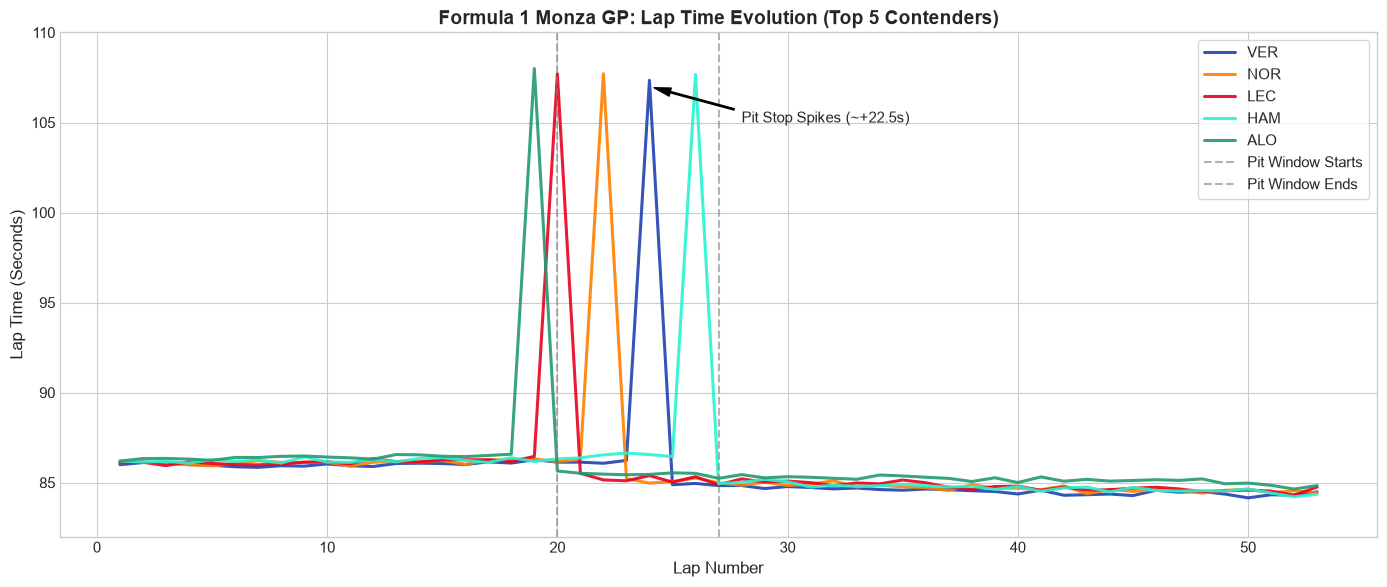

In [4]:
# 1. Race Pace Progression Over 53 Laps
plt.figure(figsize=(14, 6))

top_drivers = ["VER", "NOR", "LEC", "HAM", "ALO"]
color_map = {d["driver"]: d["color"] for d in DRIVERS_GRID}

for driver in top_drivers:
    sub = df_race[df_race["driver"] == driver]
    plt.plot(sub["lap"], sub["lap_time_s"], label=driver, color=color_map[driver], linewidth=2.2, alpha=0.9)

plt.title("Formula 1 Monza GP: Lap Time Evolution (Top 5 Contenders)", fontsize=14, fontweight='bold')
plt.xlabel("Lap Number", fontsize=12)
plt.ylabel("Lap Time (Seconds)", fontsize=12)
plt.ylim(82, 110)
plt.axvline(x=20, color='gray', linestyle='--', alpha=0.6, label='Pit Window Starts')
plt.axvline(x=27, color='gray', linestyle='--', alpha=0.6, label='Pit Window Ends')
plt.annotate("Pit Stop Spikes (~+22.5s)", xy=(24, 107), xytext=(28, 105),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


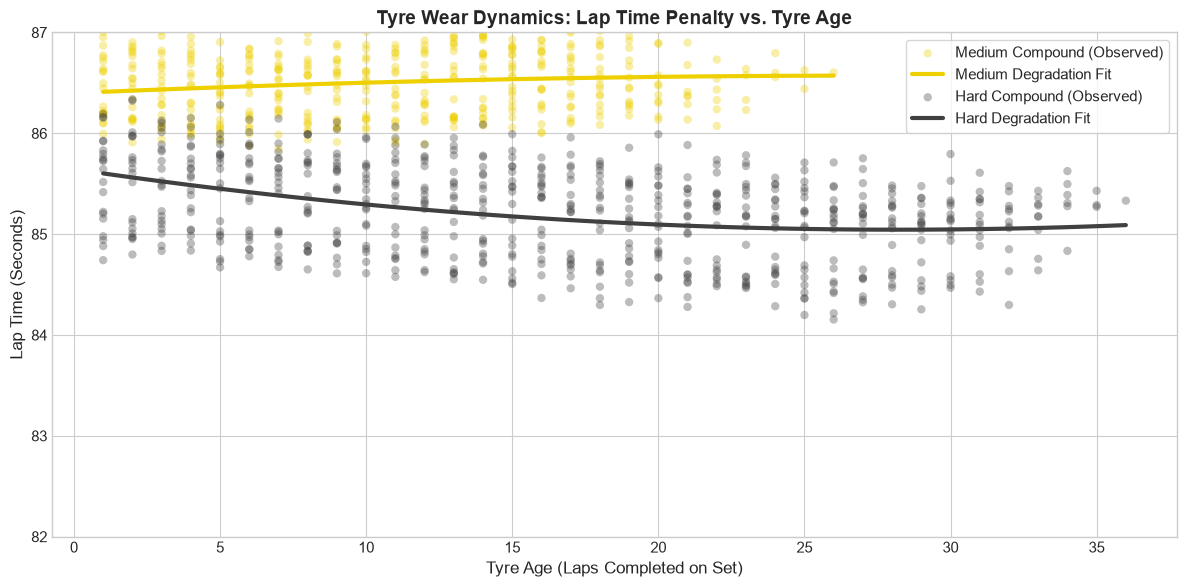

In [5]:
# 2. Tyre Degradation Curves (Medium vs. Hard Compound)
plt.figure(figsize=(12, 6))

non_pit_laps = df_race[df_race["pit_stop_this_lap"] == 0]

for compound, col in [("Medium", "#EED000"), ("Hard", "#404040")]:
    comp_data = non_pit_laps[non_pit_laps["tyre_compound"] == compound]
    plt.scatter(comp_data["tyre_age"], comp_data["lap_time_s"], 
                alpha=0.35, label=f"{compound} Compound (Observed)", color=col, edgecolors='none')
    
    # Polynomial trendline
    z = np.polyfit(comp_data["tyre_age"], comp_data["lap_time_s"], 2)
    p = np.poly1d(z)
    x_range = np.linspace(1, comp_data["tyre_age"].max(), 50)
    plt.plot(x_range, p(x_range), color=col, linewidth=3, label=f"{compound} Degradation Fit")

plt.title("Tyre Wear Dynamics: Lap Time Penalty vs. Tyre Age", fontsize=14, fontweight='bold')
plt.xlabel("Tyre Age (Laps Completed on Set)", fontsize=12)
plt.ylabel("Lap Time (Seconds)", fontsize=12)
plt.ylim(82, 87)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


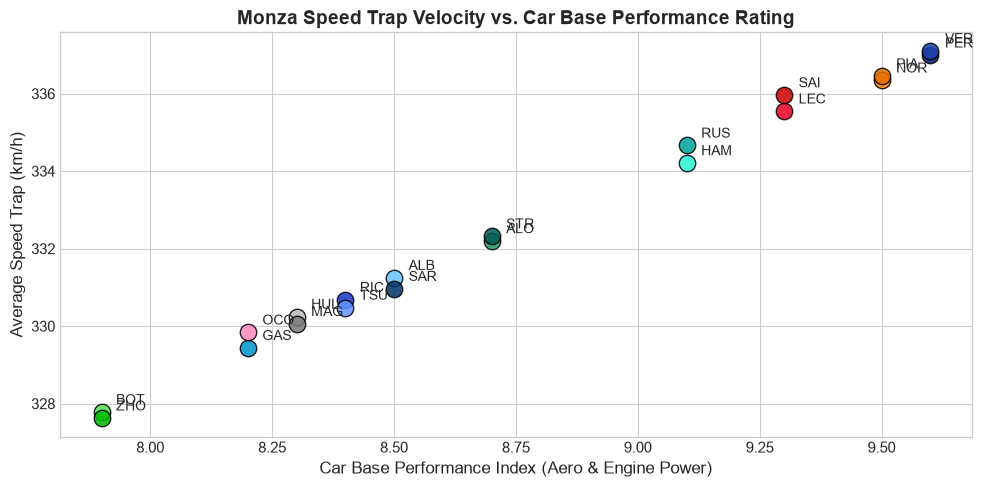

In [6]:
# 3. Straight-Line Speed vs. Car Performance Rating
plt.figure(figsize=(10, 5))

avg_speed = df_race.groupby(["driver", "car_base_performance", "team"])["speed_trap_kmh"].mean().reset_index()

for _, row in avg_speed.iterrows():
    c = color_map.get(row["driver"], "#333333")
    plt.scatter(row["car_base_performance"], row["speed_trap_kmh"], color=c, s=140, edgecolors='black', alpha=0.85)
    plt.annotate(row["driver"], (row["car_base_performance"] + 0.03, row["speed_trap_kmh"] + 0.2), fontsize=10)

plt.title("Monza Speed Trap Velocity vs. Car Base Performance Rating", fontsize=14, fontweight='bold')
plt.xlabel("Car Base Performance Index (Aero & Engine Power)", fontsize=12)
plt.ylabel("Average Speed Trap (km/h)", fontsize=12)
plt.tight_layout()
plt.show()


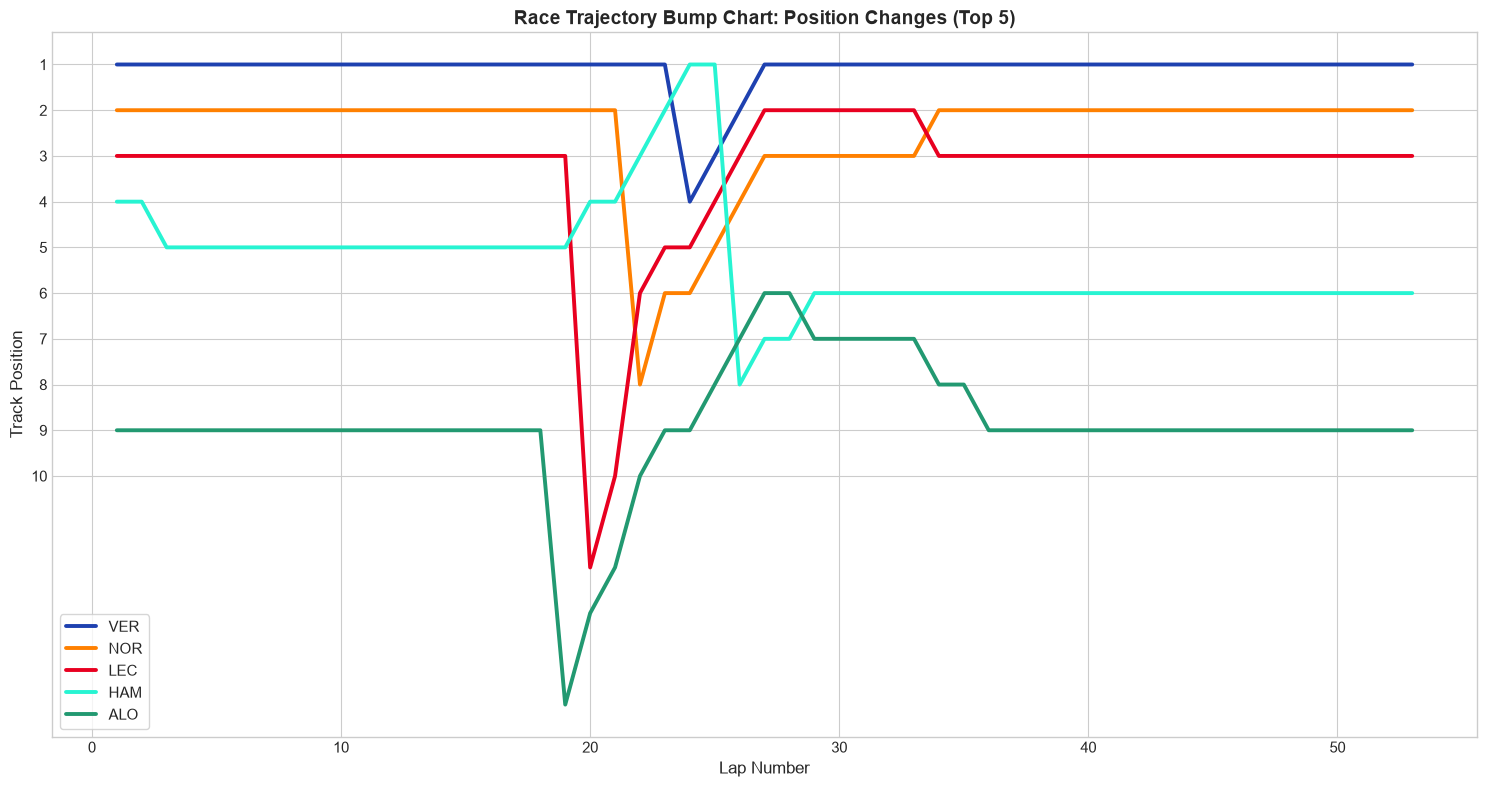

In [7]:
# 4. Leaderboard Bump Chart (Position Dynamics Across 53 Laps)
plt.figure(figsize=(15, 8))

for driver in top_drivers:
    sub = df_race[df_race["driver"] == driver]
    plt.plot(sub["lap"], sub["position"], label=driver, color=color_map[driver], linewidth=2.8)

plt.gca().invert_yaxis()  # P1 on top
plt.yticks(range(1, 11))
plt.title("Race Trajectory Bump Chart: Position Changes (Top 5)", fontsize=14, fontweight='bold')
plt.xlabel("Lap Number", fontsize=12)
plt.ylabel("Track Position", fontsize=12)
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()


### Final Race Classification (Lap 53)
Let's inspect the final podium and top 10 finishers of our simulated race:


In [8]:
podium = df_race[df_race["lap"] == 53].sort_values("position")[
    ["position", "driver", "driver_name", "team", "cumulative_time_s", "gap_to_leader_s"]
].reset_index(drop=True)

print("=== OFFICIAL MONZA GP FINAL RESULTS ===")
podium.head(10)


=== OFFICIAL MONZA GP FINAL RESULTS ===


,position,driver,driver_name,team,cumulative_time_s,gap_to_leader_s
0,1,VER,Max Verstappen,Red Bull Racing,4538.165,0.000
1,2,NOR,Lando Norris,McLaren,4544.179,6.014
2,3,LEC,Charles Leclerc,Ferrari,4545.611,7.446
3,4,PIA,Oscar Piastri,McLaren,4546.927,8.762
4,5,SAI,Carlos Sainz,Ferrari,4551.083,12.918
5,6,HAM,Lewis Hamilton,Mercedes,4552.955,14.790
6,7,PER,Sergio Perez,Red Bull Racing,4555.522,17.357
7,8,RUS,George Russell,Mercedes,4556.108,17.943
8,9,ALO,Fernando Alonso,Aston Martin,4564.229,26.064
9,10,ALB,Alexander Albon,Williams,4573.758,35.593


---
### Discussion & Analytical Reflection
1. **The Fuel-Weight / Degradation Balance**: Notice how lap times gradually drop between Laps 28 and 50 despite tyre wear! As fuel load diminishes by $1.8\text{ kg/lap}$, the reduced weight offsets tyre degradation until the final 3 laps.
2. **Deterministic Reproducibility**: Because we locked the prompt/generation seed to `42`, every participant has generated the exact same baseline data.
3. **Next Step**: Open `02_f1_race_animation.ipynb` to bring this dataset to life with a full dynamic race animation!
